# 03 — Exposure profiles and netting

**Question 4 of the project:** when the simulated value is positive, how much are we exposed to if the counterparty defaults?

1. Turn the MtM cube into counterparty exposure, netting first and then taking the positive part.
2. Measure Expected Exposure (EE), PFE at 95% and EPE through time.
3. Compare gross (no netting) with netted exposure and look at exposure distributions at 1Y, 3Y and 5Y.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
%matplotlib inline

from src.config import BASE_SIMULATION, CURVE_FILE, DISTRIBUTION_TIMES, HW_PARAMS, PFE_QUANTILE, PORTFOLIO_FILE
from src.curves import load_treasury_curve
from src.exposure import (expected_exposure, exposure_summary, gross_exposure, netted_exposure,
                          netting_set_horizons, potential_future_exposure, profile_table)
from src.instruments import load_portfolio
from src.plotting import plot_exposure_distributions, plot_exposure_profiles, plot_gross_vs_netted
from src.simulation import build_time_grid, netting_set_mtm, revalue_portfolio, simulate_paths, time_index

pd.set_option('display.float_format', '{:,.2f}'.format)
curve = load_treasury_curve(CURVE_FILE)
portfolio = load_portfolio(PORTFOLIO_FILE)
grid = build_time_grid(portfolio, step=BASE_SIMULATION.time_step)
paths = simulate_paths(HW_PARAMS, grid, BASE_SIMULATION.n_paths, np.random.default_rng(BASE_SIMULATION.seed))
cube = revalue_portfolio(portfolio, curve, paths)
print('cube (trades, paths, dates):', cube.shape)

cube (trades, paths, dates): (10, 10000, 121)


## 1. From values to exposure

If the counterparty defaults at $t$, we lose the portfolio's value only when it is positive to us. A negative value is owed by us and still has to be paid. Under a legal netting agreement, the trades in a netting set are closed out as one amount, so netting is applied **on each path and date before** the positive part:

$$E_{\text{net}}(t) = \max\Big(\sum_{i\in\text{NS}} V_i(t),\,0\Big) \;\le\; E_{\text{gross}}(t) = \sum_{i\in\text{NS}} \max(V_i(t),0)$$

The inequality holds on every path because the positive part is subadditive; `tests/test_exposure.py` checks it on every path and date.

- $EE(t)$ = average of $E(t)$ across paths.
- $PFE_{95\%}(t)$ = the 95th percentile across paths, using the empirical inverse CDF, so it is an actual simulated value.
- **EPE (time-average EE)** $= \frac1T\int_0^T EE(t)\,dt$ over the netting set's whole life. It is not the regulatory Effective EPE, which averages the running maximum of EE over the first year only.

In [2]:
netted, gross = netted_exposure(cube, portfolio), gross_exposure(cube, portfolio)
summary = exposure_summary(grid, netted, gross, netting_set_horizons(portfolio), PFE_QUANTILE)
summary

,netting_set_id,horizon,epe_netted,epe_gross,netting_reduction,peak_ee_netted,peak_ee_time,peak_pfe95_netted,peak_pfe_time
0,NS_A,10.00,"720,456.16","3,498,208.59",0.79,"1,576,589.05",0.42,"2,056,053.01",0.92
1,NS_B,8.00,"722,685.56","787,863.33",0.08,"1,644,213.92",1.67,"5,623,326.16",1.67


## 2. EE and PFE through time

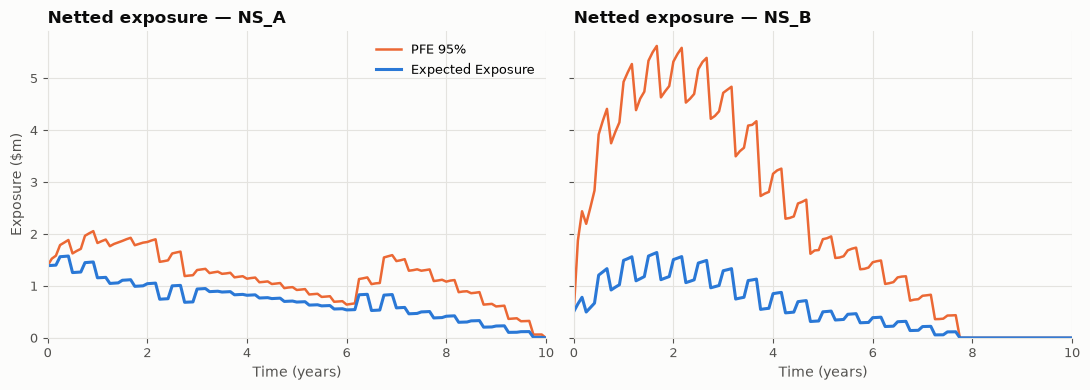

In [3]:
profiles = profile_table(grid, netted, gross, PFE_QUANTILE)
by_set = {ns: rows for ns, rows in profiles.groupby('netting_set_id', sort=False)}
ee = {ns: rows['ee_netted'].to_numpy() for ns, rows in by_set.items()}
pfe = {ns: rows['pfe_netted'].to_numpy() for ns, rows in by_set.items()}
fig = plot_exposure_profiles(grid, ee, pfe, PFE_QUANTILE)

**Reading the profiles**

- **Shape:** an uncollateralized swap book's exposure first rises as rates diffuse away from today, then falls as the remaining cash flows run off. NS_B peaks around 1.5–2 years. NS_A starts high because it is already in the money today (+\$1.39m), and then declines.
- **PFE vs EE:** PFE is a tail statistic, the exposure exceeded on only 5% of paths. It is a credit-limit measure, not an expected loss. CVA (Phase D) uses EE.
- **Sawtooth:** after a quarterly floating-only date we have just received a coupon, so value and exposure drop. After a semiannual date we have also paid the larger fixed coupon, so a payer book's value jumps back up.
- **NS_A after 6Y:** when A3 (a payer) matures at 6Y, the book becomes receiver-heavy until A2 matures at 7Y, and PFE rises for that year.

In [4]:
table = profiles[profiles['time'].isin([0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0])].copy()
table[['ee_netted', 'pfe_netted', 'ee_gross', 'pfe_gross']] /= 1e6
table.rename(columns=lambda c: c + ' ($m)' if c.startswith(('ee', 'pfe')) else c)

,netting_set_id,time,ee_netted ($m),pfe_netted ($m),ee_gross ($m),pfe_gross ($m)
0,NS_A,0.00,1.39,1.39,2.54,2.54
6,NS_A,0.50,1.26,1.63,3.72,7.47
12,NS_A,1.00,1.16,1.83,4.44,9.57
24,NS_A,2.00,1.04,1.85,5.00,11.36
36,NS_A,3.00,0.94,1.31,5.02,11.23
60,NS_A,5.00,0.69,0.92,4.29,9.80
84,NS_A,7.00,0.58,1.48,2.72,6.45
121,NS_B,0.00,0.51,0.51,0.77,0.77
127,NS_B,0.50,1.21,3.92,1.40,4.15
133,NS_B,1.00,1.49,4.93,1.68,5.23


## 3. Gross vs netted exposure

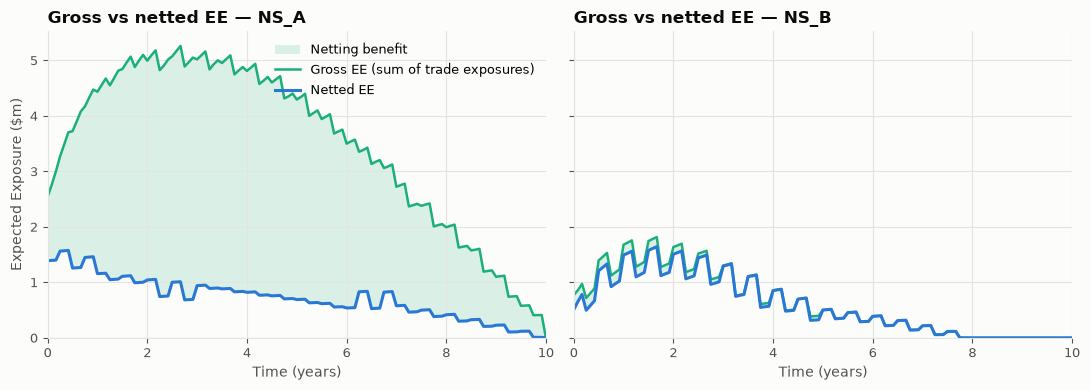

In [5]:
fig = plot_gross_vs_netted(grid, ee, {ns: rows['ee_gross'].to_numpy() for ns, rows in by_set.items()})

- **NS_A:** payers and receivers on similar maturities offset each other. Netting removes about four-fifths of the gross exposure.
- **NS_B:** almost every trade gains when rates rise and loses when they fall. Netting helps only while B4, the one receiver, is alive (until 3Y); after that, gross equals netted.

How much netting helps depends on how directionally balanced the netting set is, not on how many trades it holds.

## 4. Exposure distributions

Exposure is the positive part of the netted value. Colored bars are paths with exposure; grey bars are paths where we would owe the counterparty, so its default costs us nothing.

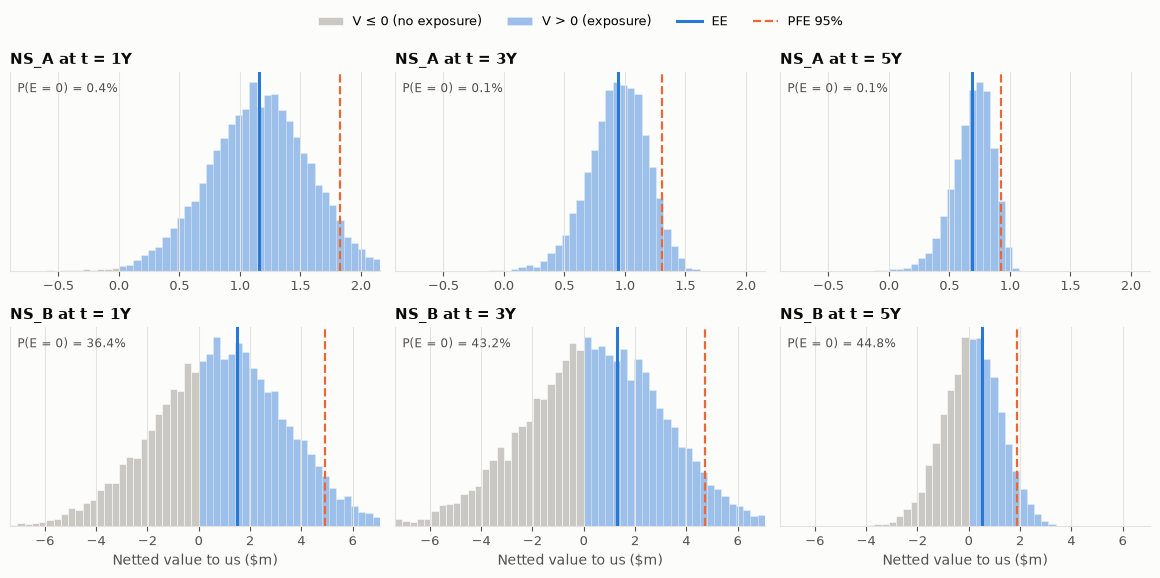

In [6]:
fig = plot_exposure_distributions(grid, netting_set_mtm(cube, portfolio), DISTRIBUTION_TIMES, PFE_QUANTILE)

## 5. Checks (also enforced in `tests/test_exposure.py`)

In [7]:
rows = []
values = netting_set_mtm(cube, portfolio)
for ns in netted:
    pfe_t = potential_future_exposure(netted[ns], PFE_QUANTILE)
    positive = pfe_t > 0
    share_above = (netted[ns] > pfe_t).mean(axis=0)[positive]
    rows.append({
        'netting_set': ns,
        'min exposure (>= 0)': netted[ns].min(),
        'max(netted - gross) (<= 0)': (netted[ns] - gross[ns]).max(),
        'EE(0) - max(V0, 0)': expected_exposure(netted[ns])[0] - max(values[ns][0, 0], 0.0),
        'share of paths above PFE (max, <= 5%)': share_above.max(),
    })
pd.DataFrame(rows)

,netting_set,min exposure (>= 0),max(netted - gross) (<= 0),"EE(0) - max(V0, 0)","share of paths above PFE (max, <= 5%)"
0,NS_A,0.00,0.00,-0.00,0.05
1,NS_B,0.00,0.00,0.00,0.05
